# Figure 4 (new) — overlap by strategy · ΔOverlap field · sub-additivity

Three panels, all in **mining-biodiversity overlap** (mining footprint × rarity-weighted species richness; *species-range equivalents*) — the metric formerly labelled "affected species range (ASR)".

**(a)** Total overlap under the four corner strategies — **BAU** (φ0, β0), **CE** (φ1, β0), **CON** (φ0, β_CON), **IAP** (φ1, β_CON) — with anti-diagonal demand/reserve uncertainty bars (lower = DL-RH-AL, upper = DH-RL-AH). **(b)** ΔOverlap reduction (% vs BAU·β0) over the (φ, β) plane, four signposts marked (β_CON = 0.7 knee; all-median DM-RM settings). **(c)** Sub-additivity as a **27-point global cloud**: one point per demand/reserve/extraction–area parameter combination (3³ = 27), modeled joint reduction ΔOverlap_IAP vs the expected sum ΔOverlap_CE + ΔOverlap_CON. Every combination lands below the 1:1 line ⇒ the two levers are complementary, not synergistic. The fit is forced **through the origin** (expected 0 ⇒ modeled 0), so its slope is directly the sub-additivity ratio. No error bars: the parameter ensemble *is* the scatter.

> **Data:** BAU & CE (β0) under all 27 combos from `biodiversity-risk-summary-B0-DRA-factorial.csv`; CON (BAU·β0.7) & IAP (CE·β0.7) under all 27 combos from `biodiversity-risk-summary-B0.7-signposts-DRA-factorial.csv` (refreshed after bounding spatial turnover shares on 2026-10-12). The per-economy scatter is the Extended-Data cell at the bottom.

Panel **a** = old Fig-4 panel A (overlap units), panel **b** = new Fig-4 panel a, panel **c** = old Fig-4 panel C re-cast as a 27-point global cloud (option ③).

---
**Inputs** (all-median DM-RM settings unless noted):
- `results/biodiversity-risk/biodiversity-risk-summary-DM-RM.csv` — overlap for the 11×13 (φ, β) sweep (field + all-median bar values)
- `results/biodiversity-risk/biodiversity-risk-summary-B0-DRA-factorial.csv` — BAU/CE × 27 (D,R,A) at β0 (panel c)
- `results/biodiversity-risk/biodiversity-risk-summary-B0.7-signposts-DRA-factorial.csv` — CON/IAP × 27 (D,R,A) at β0.7 (panel c)
- `results/biodiversity-risk/mining-biodiversity-overlap-2050-{BAU,CE}-B{0.00,0.70}-50km-{DL-RH-AL,DH-RL-AH}.tif` — signpost bound rasters (bar error-bars)
- `results/country-rasters/country-raster-eck4-50km.tif` — country mask (Extended-Data per-economy scatter)

In [ ]:
import numpy as np
import pandas as pd
import rasterio as rio
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import linregress
from pathlib import Path

In [ ]:
ROOT    = Path.cwd().parent
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)
BR      = RESULTS / 'biodiversity-risk'

In [ ]:
DEMAND, RESERVE = 'M', 'M'                       # median demand / reserve settings
SCENARIOS = ['BAU', 'CE10', 'CE20', 'CE30', 'CE40', 'CE50', 'CE60', 'CE70', 'CE80', 'CE90', 'CE']   # CE-ambition φ (0,.1,…,1; 11 levels)
BETAS     = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.90, 0.95, 1.0]
BETA_CON  = 0.7                                  # conservation-siting knee; CON & IAP signposts sit at this β
PHI = {'BAU': 0.0, 'CE10': 0.1, 'CE20': 0.2, 'CE30': 0.3, 'CE40': 0.4, 'CE50': 0.5,
       'CE60': 0.6, 'CE70': 0.7, 'CE80': 0.8, 'CE90': 0.9, 'CE': 1.0}
# the 4 corner strategies as (scenario φ, beta): CON = BAU·β_CON, IAP = CE·β_CON
SIGN_SCN = {'BAU': ('BAU', 0.0), 'CE': ('CE', 0.0), 'CON': ('BAU', BETA_CON), 'IAP': ('CE', BETA_CON)}

In [ ]:
# --- ΔOverlap field data: overlap for the full (φ, β) sweep, vs the BAU·β0 baseline ---
# 'overlap' = mining-biodiversity overlap (species-range equivalents; formerly 'affected_species_range').
df = pd.read_csv(BR / f'biodiversity-risk-summary-D{DEMAND}-R{RESERVE}.csv')
overlap_bau = df[(df.scenario == 'BAU') & (df.beta == 0.0)]['overlap'].iloc[0]
df['z_dOverlap'] = 100 * (1 - df['overlap'] / overlap_bau)        # ΔOverlap field: reduction (% vs BAU·β0)
df['scenario'] = pd.Categorical(df['scenario'], categories=SCENARIOS, ordered=True)
df = df.sort_values(['scenario', 'beta']).reset_index(drop=True)
print(f'sweep rows: {len(df)} | BAU·β0 overlap = {overlap_bau:.3f} species-range equivalents')

sweep rows: 143 | BAU·β0 overlap = 2.646 species-range equivalents


In [ ]:
# --- panel-c inputs: 27-point GLOBAL sub-additivity cloud --------------------------------
# One point per (demand, reserve, extraction–area) combination (3³ = 27). BAU & CE (β0) from the β0 factorial;
# CON (BAU·β0.7) & IAP (CE·β0.7) from the regenerated β0.7 signpost factorial. expected =
# ΔOverlap_CE + ΔOverlap_CON, modeled = ΔOverlap_IAP, all GLOBAL totals under the SAME combo.
def _ov(scn, beta, tag):                                  # signpost bound raster (used by the bar error-bars)
    return rio.open(BR / f'mining-biodiversity-overlap-2050-{scn}-B{beta:.2f}-50km-{tag}.tif').read(1)
def _glob(scn, beta, tag):
    return float(_ov(scn, beta, tag).sum())

_key  = ['demand', 'reserve', 'area']
_fac0 = pd.read_csv(BR / 'biodiversity-risk-summary-B0-DRA-factorial.csv')                 # BAU,CE,… @ β0
_fac6 = pd.read_csv(BR / 'biodiversity-risk-summary-B0.7-signposts-DRA-factorial.csv')     # CON,IAP @ β0.7
_p0   = _fac0[_fac0.scenario.isin(['BAU', 'CE'])].pivot_table(index=_key, columns='scenario', values='overlap')
_p6   = _fac6.pivot_table(index=_key, columns='scenario', values='overlap')
g = _p0.join(_p6)
g['expected'] = (g['BAU'] - g['CE']) + (g['BAU'] - g['CON'])
g['modeled']  =  g['BAU'] - g['IAP']
subadd_glob = g.reset_index()
# fit forced THROUGH THE ORIGIN: expected=0 ⇒ modeled=0 (both levers off ⇒ no reduction). The
# through-origin OLS slope (Σxy/Σx²) IS the sub-additivity ratio = modeled / additive expectation.
sg_slope = float(np.sum(subadd_glob.expected * subadd_glob.modeled) / np.sum(subadd_glob.expected ** 2))
print(f'27-point global cloud (fit through origin): slope={sg_slope:.3f}; '
      f'all below 1:1: {bool((subadd_glob.modeled < subadd_glob.expected).all())}; '
      f'pooled ratio modeled/expected={subadd_glob.modeled.sum()/subadd_glob.expected.sum():.3f}')

27-point global cloud (fit through origin): slope=0.879; all below 1:1: True; pooled ratio modeled/expected=0.884


In [ ]:
# --- panel-a inputs: total overlap under the four corner strategies -----------------------
# all-median height from the summary table (matches the field corners & main text); error bars bracket
# the anti-diagonal demand/reserve corners (DL-RH-AL / DH-RL-AH), summed globally from the rasters.
def _df_overlap(scn, b):
    return float(df[(df.scenario == scn) & (np.isclose(df.beta, b))]['overlap'].iloc[0])

rows = []
for nm, (scn, b) in SIGN_SCN.items():
    c  = _df_overlap(scn, b)
    lo = _glob(scn, b, 'DL-RH-AL')
    hi = _glob(scn, b, 'DH-RL-AH')
    rows.append({'scenario': nm, 'overlap': c, 'overlap_l': min(c, lo, hi), 'overlap_u': max(c, lo, hi)})
total_overlap = pd.DataFrame(rows).set_index('scenario')
print(total_overlap.round(3))
print('reduction vs BAU:',
      {k: f'{v:.0%}' for k, v in (1 - total_overlap['overlap'] / total_overlap.loc['BAU', 'overlap']).items()})

          overlap  overlap_l  overlap_u
scenario                               
BAU         2.646      1.987      4.459
CE          2.283      1.745      3.651
CON         1.158      0.815      2.043
IAP         0.961      0.700      1.669
reduction vs BAU: {'BAU': '0%', 'CE': '14%', 'CON': '56%', 'IAP': '64%'}


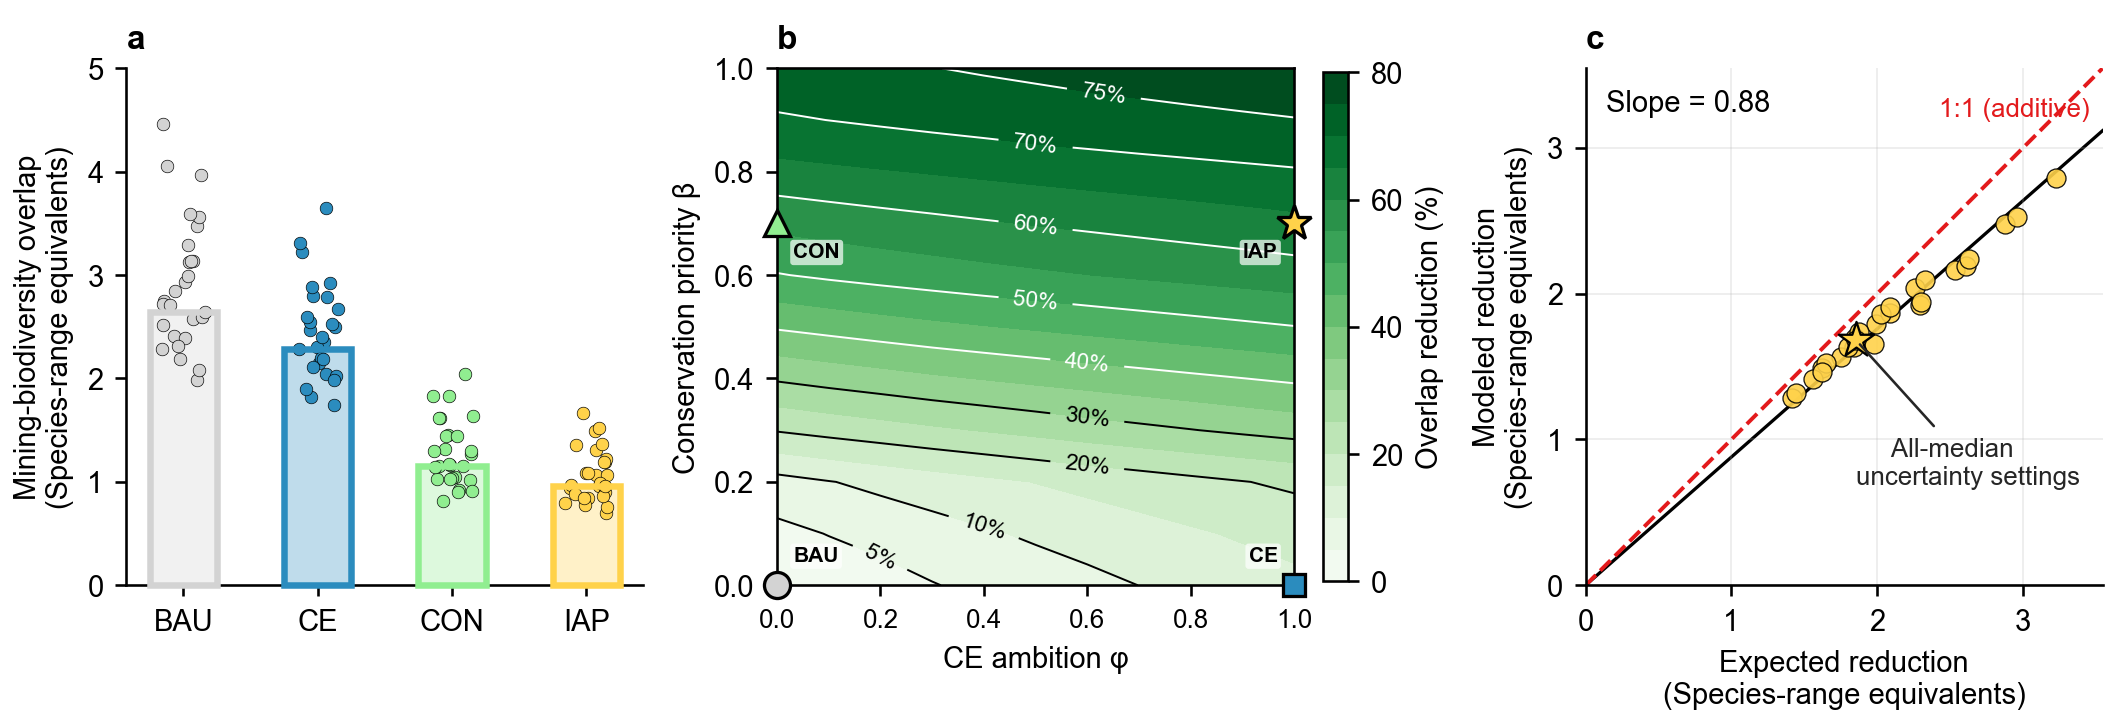

In [ ]:
# ============================================================
# Figure 4 (new) — three panels in mining-biodiversity overlap units (species-range equivalents):
#   a  total overlap by strategy : BAU / CE / CON / IAP bars (all-median) + 27-combo uncertainty strip
#   b  ΔOverlap field            : overlap reduction (% vs BAU·β0) over (φ, β)   [new Fig-4 panel a]
#   c  sub-additivity (27-pt)    : modeled ΔOverlap_IAP vs expected ΔOverlap_CE+ΔOverlap_CON, per (D,R,A) combo
# Four signposts: BAU (φ0,β0) · CE (φ1,β0) · CON (φ0,β_CON) · IAP (φ1,β_CON)  [β_CON = 0.7 knee].
# ============================================================
plt.rcParams['font.family'] = 'Arial'

# --- field grid (panel b) ---
betas = np.sort(df['beta'].unique())
xi    = np.array([PHI[s] for s in SCENARIOS])                       # CE-ambition φ (0..1)
ZB    = df.pivot(index='beta', columns='scenario', values='z_dOverlap').reindex(index=betas, columns=SCENARIOS).values
_ref  = [('BAU', 0.0), ('CE20', 0.2), ('CE40', 0.4), ('CE60', 0.6), ('CE80', 0.8), ('CE', 1.0)]
xt    = [p for _, p in _ref]
xtl   = [f'{p:.1f}' for _, p in _ref]

# --- signpost markers shared by panels a (bar colour) & b (field markers); CON = light green ---
SIGN = {'BAU': ('o', 'lightgray', 8), 'CON': ('^', 'lightgreen', 8), 'CE': ('s', '#2b8cbe', 7), 'IAP': ('*', '#ffd24a', 11)}
LOC  = {'BAU': ('BAU', 0.0), 'CON': ('BAU', BETA_CON), 'CE': ('CE', 0.0), 'IAP': ('CE', BETA_CON)}
def _signpost(ax, x, y, nm, dx, dy, ha, va):                  # one marker + label with a light halo
    mk, fc, ms = SIGN[nm]
    ax.plot(x, y, marker=mk, mfc=fc, mec='k', mew=1.0, ms=ms, ls='none', zorder=9, clip_on=False)
    ax.annotate(nm, (x, y), textcoords='offset points', xytext=(dx, dy), ha=ha, va=va,
                fontsize=6.5, fontweight='bold', zorder=10,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.7))
def _corners(ax):                                            # signposts on a (φ, β) field, labels nudged inward
    for nm, (scn, b) in LOC.items():
        px, py = PHI[scn], b
        dx = 5 if px == 0 else -5; dy = 6 if py == 0 else -6
        _signpost(ax, px, py, nm, dx, dy, 'left' if px == 0 else 'right', 'bottom' if py == 0 else 'top')

fig, axes = plt.subplots(1, 3, figsize=(9.0, 3), constrained_layout=True)

# a -- total overlap by strategy: bars (all-median M·M·M) + STRIP of all 27 (D,R,A) uncertainty combos.
#      Each strip uses its scenario's signpost colour, matching the corresponding bar and panel-b marker.
ax_a  = axes[0]
order = ['BAU', 'CE', 'CON', 'IAP']
vals  = total_overlap.loc[order, 'overlap'].values                       # all-median (M·M·M) bar heights
bar_c = [SIGN[s][1] for s in order]                                      # bar colours echo the panel-b signposts
ax_a.bar(np.arange(4), vals, color=bar_c, ec='k', width=0.5, lw=0, alpha=0.3, zorder=2)
ax_a.bar(np.arange(4), vals, color='none', ec=bar_c, width=0.5, lw=2.0, alpha=1.0, zorder=10, clip_on=False)
# strip: all 27 (D,R,A) combos per strategy; colour identifies the scenario.
_rng     = np.random.default_rng(0)
for i, s in enumerate(order):
    _xj = i + _rng.uniform(-0.16, 0.16, len(subadd_glob))
    ax_a.scatter(_xj, subadd_glob[s].values, c=SIGN[s][1], s=15, ec='k', lw=0.2, zorder=6)
ax_a.set_xticks(np.arange(4)); ax_a.set_xticklabels(order)
ax_a.set_ylim(0, 5)
ax_a.set_ylabel('Mining-biodiversity overlap\n(Species-range equivalents)', fontsize=9)
ax_a.set_box_aspect(1)
ax_a.set_title('a', loc='left', fontweight='bold', fontsize=14)
ax_a.spines['top'].set_visible(False); ax_a.spines['right'].set_visible(False)

# for i in range(1, 4):                                                    # % reduction vs BAU above each strategy's strip
    # ax_a.annotate(f'-{1 - vals[i] / vals[0]:.0%}', (i, subadd_glob[order[i]].max()),
                #   textcoords='offset points', xytext=(0, 5), ha='center', va='bottom', fontsize=7.5, color='0.25')

# b -- ΔOverlap field over (φ, β)  [new Fig-4 panel a]
ax_b = axes[1]
cf   = ax_b.contourf(xi, betas, ZB, levels=np.linspace(0, 80, 17), cmap='Greens', norm=Normalize(0, 80))
cl1  = ax_b.contour(xi, betas, ZB, levels=[40, 50, 60, 70, 75], colors='w', linewidths=0.6)
cl2  = ax_b.contour(xi, betas, ZB, levels=[5, 10, 20, 30], colors='k', linewidths=0.6)
ax_b.clabel(cl1, fmt='%d%%', fontsize=7); ax_b.clabel(cl2, fmt='%d%%', fontsize=7)
_corners(ax_b)
ax_b.set_box_aspect(1)
ax_b.set_xticks(xt); ax_b.set_xticklabels(xtl, fontsize=8)
ax_b.set_xlabel('CE ambition φ', fontsize=9)
ax_b.set_ylabel('Conservation priority β', fontsize=10)
ax_b.set_title('b', loc='left', fontweight='bold', fontsize=14)
fig.colorbar(cf, ax=ax_b, shrink=0.94, pad=0.02, ticks=np.arange(0, 81, 20)).set_label('Overlap reduction (%)', fontsize=9)

# c -- 27-point GLOBAL sub-additivity cloud (one point per (D,R,A) combo); below 1:1 ⇒ sub-additive
ax_c = axes[2]
ax_c.scatter(subadd_glob.expected, subadd_glob.modeled, s=34, c=SIGN['IAP'][1], ec='k', lw=0.4,
             alpha=0.9, zorder=3)
_med = subadd_glob[(subadd_glob.demand == 'M') & (subadd_glob.reserve == 'M') & (subadd_glob.area == 'M')]
_med_x, _med_y = float(_med.expected.iloc[0]), float(_med.modeled.iloc[0])
ax_c.scatter(_med_x, _med_y, s=130, marker='*', c=SIGN['IAP'][1], ec='k', lw=0.7, zorder=5)
ax_c.annotate('     All-median\nuncertainty settings', xy=(_med_x, _med_y), xytext=(0, -30),
              textcoords='offset points', ha='left', va='top', fontsize=8, color='0.15',
              arrowprops=dict(arrowstyle='-', color='0.15', lw=0.8), zorder=6)
lim = float(subadd_glob[['expected', 'modeled']].to_numpy().max()) * 1.10
ax_c.plot([0, lim], [0, lim], '--', color='#e31a1c', lw=1.2, zorder=2)              # 1:1 = additive
ax_c.plot([0, lim], [0, sg_slope * lim], '-', color='k', lw=1.0, zorder=1)          # fit THROUGH ORIGIN (slope<1 ⇒ sub-additive)
ax_c.set_xlim(0, lim); ax_c.set_ylim(0, lim); ax_c.set_box_aspect(1)
ax_c.annotate(f'Slope = {sg_slope:.2f}', (0.04, 0.96), xycoords='axes fraction',
              va='top', ha='left', fontsize=9)
ax_c.annotate('1:1 (additive)', (lim, lim), textcoords='offset points', xytext=(-4, -9),
              ha='right', va='top', fontsize=8, color='#e31a1c')
ax_c.set_xlabel(r'Expected reduction'
                + '\n(Species-range equivalents)', fontsize=9)
ax_c.set_ylabel(r'Modeled reduction'
                + '\n(Species-range equivalents)', fontsize=9)
ax_c.grid(alpha=0.25, lw=0.5)
ax_c.spines['top'].set_visible(False); ax_c.spines['right'].set_visible(False)
ax_c.set_title('c', loc='left', fontweight='bold', fontsize=14)

# Final PDF width is at most 180 mm; standard text is 5-7 pt at final size.
# Keep text editable by embedding TrueType fonts (no Type 3 glyphs).
from final_figure_export import export_final_figure
export_report = export_final_figure(fig, FIGURES / 'Figure-4')
if plt.get_backend().lower() != 'agg':
    plt.show()


## Reading the figure

- **a — most of the biodiversity gain comes from β (conservation siting), not φ.** CE alone (φ1, β0) trims overlap only modestly; CON (β_CON siting) does far more; IAP (both) is lowest. Bars show the all-median (M·M·M) settings; the overlaid strip contains all 27 demand/reserve/extraction–area parameter combinations, with each strip coloured by its scenario to match the bar and signpost.
- **b — the (φ, β) plane.** Moving up β sweeps ΔOverlap from a few % to ~75–79%; moving right along φ adds only a modest lift at fixed β. The four signposts mark the corner strategies (β_CON = 0.7 knee).
- **c — complementary, not synergistic.** Across **all 27** demand/reserve/extraction–area parameter combinations, the **global** joint reduction ΔOverlap_IAP sits below the additive sum ΔOverlap_CE + ΔOverlap_CON (every point below 1:1). The through-origin fit has slope < 1 — i.e. the joint reduction realises only ~88% of the additive expectation. No error bars: the 27-combination ensemble *is* the scatter.

All panels are vs the **BAU·β0** baseline. Panels a–b use all-median D-M/R-M inputs; the red star in c marks the D-M/R-M/A-M settings.

### In main text

In [ ]:
# Main-text intervals: extrema over the same 27 global outcomes plotted in a.
# Preserve the central scenario totals used by the bars and response surface.
assert len(g) == 27 and g.index.is_unique
expected_combinations = pd.MultiIndex.from_product([list('LMH')] * 3, names=g.index.names)
text_factorial = g[['BAU', 'CE', 'CON', 'IAP']].reindex(expected_combinations)
assert np.isfinite(text_factorial.to_numpy()).all()
text_total_overlap = total_overlap.copy()
for scenario in ['BAU', 'CE', 'CON', 'IAP']:
    samples = text_factorial[scenario]
    np.testing.assert_allclose(samples.loc[('M', 'M', 'M')],
                               total_overlap.loc[scenario, 'overlap'], rtol=1e-6, atol=1e-8)
    text_total_overlap.loc[scenario, 'overlap_l'] = samples.min()
    text_total_overlap.loc[scenario, 'overlap_u'] = samples.max()

a_1 = 1 - text_total_overlap.loc['CE',  'overlap'] / text_total_overlap.loc['BAU', 'overlap']
a_2 = 1 - text_total_overlap.loc['CON', 'overlap'] / text_total_overlap.loc['BAU', 'overlap']
a_3 = 1 - text_total_overlap.loc['IAP', 'overlap'] / text_total_overlap.loc['BAU', 'overlap']
a_4 = text_total_overlap.loc['BAU', 'overlap']
a_5 = text_total_overlap.loc['BAU', 'overlap_l']
a_6 = text_total_overlap.loc['BAU', 'overlap_u']
a_7 = text_total_overlap.loc['IAP', 'overlap']
a_8 = text_total_overlap.loc['IAP', 'overlap_l']
a_9 = text_total_overlap.loc['IAP', 'overlap_u']

print(f'When applied independently, CE strategies reduce global mining-biodiversity overlap by {a_1:.0%} relative to BAU, \n\
whereas strategic spatial planning delivers a substantially larger reduction of {a_2:.0%}.')
print('')
print(f'When implemented together, the IAP scenario achieves the strongest overall outcome, \n\
lowering total overlap by {a_3:.0%}, from {a_4:.1f} (uncertainty range: {a_5:.1f}-{a_6:.1f}) to {a_7:.1f} (uncertainty range: {a_8:.1f}-{a_9:.1f}) species-range equivalents (Figure 4a).')

When applied independently, CE strategies reduce global mining-biodiversity overlap by 14% relative to BAU, 
whereas strategic spatial planning delivers a substantially larger reduction of 56%.

When implemented together, the IAP scenario achieves the strongest overall outcome, 
lowering total overlap by 64%, from 2.6 (uncertainty range: 2.0-4.5) to 1.0 (uncertainty range: 0.7-1.7) species-range equivalents (Figure 4a).
